In [1]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.ANT_utils import *
from utils.file_manager import LOCAL_BASE_DIRECTORY, quantDiffusionPath

file_manager = quantDiffusionPath()

gc.collect()

0

# 1) Load Data

In [2]:
# 데이터 로드 (indices.csv: 6개 자산의 가격 데이터)
df = pd.read_csv("./data/indices.csv")
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')
df.set_index('Date', inplace=True)
df = df.apply(pd.to_numeric).astype(float)

# 로그 수익률 계산
log_returns = np.log1p(df.pct_change()).dropna().values

# TS: 각 채널(자산)별 시계열 리스트
TS = [log_returns[:, i] for i in range(log_returns.shape[1])]

print(f"데이터 shape: {log_returns.shape}")
print(f"자산 수: {len(TS)}")
print(f"시계열 길이: {len(TS[0])}")

데이터 shape: (5720, 6)
자산 수: 6
시계열 길이: 5720


# 2) Define scheduler

In [3]:
scheduler = 'cosine'
T = 75
tau = 1.5

In [4]:
betas = return_betas(scheduler, tau, T, beta_0 = 1e-5, beta_T = 0.5)

# 3) ANT score

## 3-1) Autocorrelation

In [5]:
out = get_scheduler_utils(T, betas)
sqrt_one_minus_beta, alphas, alphas_cumprod, sqrt_alphas_cumprod, sqrt_one_minus_alphas_cumprod, posterior_variance = out

TS_acf = []
for ts in TS:
    ts_processed = preprocess_data(ts)
    acf = return_acf(ts_processed, sqrt_alphas_cumprod, sqrt_one_minus_alphas_cumprod, T)
    TS_acf.append(acf)
    
TS_acf = np.array(TS_acf)

In [6]:
# NaN 값이 있는 시계열 제거
non_nan_index = np.where(np.isnan(TS_acf[:, 0, :]).sum(axis=1) == 0)[0]
TS_acf = TS_acf[non_nan_index]
print(f"유효한 시계열 수: {len(non_nan_index)}")

유효한 시계열 수: 6


In [7]:
N,T,L = TS_acf.shape
print(f'[N] # of TS: {N}')
print(f'[T] # of Diffusion Steps: {T}')
print(f'[L] Length of TS: {L}')

[N] # of TS: 6
[T] # of Diffusion Steps: 75
[L] Length of TS: 5720


## 3-2) Non-stationarity curve
- statistics: `IAAT`

In [8]:
IAAT, scaled_IAAT = get_mIAAT_list(TS_acf, np.var(TS, axis=1))

## 3-3) ANT score

In [9]:
ANT_score = calculate_ANT_score(IAAT, scaled_IAAT)
ANT_score

0.19301281543240373

# 4) Visualization

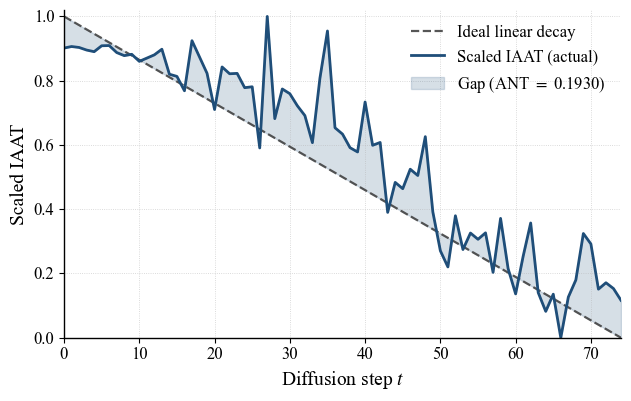

In [12]:
import matplotlib as mpl

mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 13,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'legend.fontsize': 12,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.linewidth': 1.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

steps = np.arange(len(scaled_IAAT))
ideal = np.linspace(1, 0, len(scaled_IAAT))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
fig.patch.set_alpha(0.0)
ax.patch.set_alpha(0.0)

ax.plot(steps, ideal, linestyle='--', color='#444444',
        linewidth=1.6, alpha=0.9, label='Ideal linear decay')
ax.plot(steps, scaled_IAAT, color='#1f4e79',
        linewidth=2.0, label='Scaled IAAT (actual)')
ax.fill_between(steps, scaled_IAAT, ideal,
                color='#1f4e79', alpha=0.18,
                label=fr'Gap (ANT $=$ {ANT_score:.4f})')

ax.set_xlabel(r'Diffusion step $t$')
ax.set_ylabel(r'Scaled IAAT')
ax.set_xlim(0, len(scaled_IAAT) - 1)
ax.set_ylim(0, max(1.02, scaled_IAAT.max() * 1.02))
ax.grid(True, linestyle=':', linewidth=0.6, alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

leg = ax.legend(frameon=False, loc='upper right')

fig.tight_layout()
fig.savefig('ANT_score.pdf', transparent=True, bbox_inches='tight')
fig.savefig('ANT_score.png', dpi=400, transparent=True, bbox_inches='tight')
plt.show()

# 5) Test

In [ ]:
# beta_0_list = [1e-5, 1e-4]
# beta_T_list = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]


# results = []
# best_score = float('inf')
# sched = 'linear'

# for T in [100, 300, 500, 1000, 1300, 1500]:
#     for beta_0 in beta_0_list:
#         for beta_T in beta_T_list:
#             print(f"T={T}, β₀={beta_0}, β_T={beta_T}")
#             betas_test = return_betas(sched, 2.0, T, beta_0=beta_0, beta_T=beta_T)
#             out_test = get_scheduler_utils(T, betas_test)
#             _, _, _, sqrt_ac, sqrt_omac, _ = out_test
            
#             TS_acf_test = []
#             for ts in TS:
#                 ts_p = preprocess_data(ts)
#                 acf_val = return_acf(ts_p, sqrt_ac, sqrt_omac, T)
#                 TS_acf_test.append(acf_val)

#             TS_acf_test = np.array(TS_acf_test)
            
#             IAAT_t, scaled_IAAT = get_mIAAT_list(TS_acf_test, np.var(TS, axis=1))
#             score = calculate_ANT_score(IAAT_t, scaled_IAAT)
#             results.append({'scheduler': sched, 'T': T, 'beta_0': beta_0, 'beta_T': beta_T, 'ANT_score': score})
            
#             # Best가 갱신될 때마다 그래프 출력
#             if score < best_score:
#                 best_score = score
#                 print(f"[New Best] {sched}, β₀={beta_0}, β_T={beta_T} → Score: {score:.4f}")
                
#                 plt.figure(figsize=(10, 5))
#                 plt.plot(scaled_IAAT, label='Scaled IAAT (Actual)', linewidth=2)
#                 plt.plot(np.linspace(1, 0, len(scaled_IAAT)), '--', label='Ideal Linear Decay', linewidth=2, alpha=0.7)
#                 plt.fill_between(range(len(scaled_IAAT)), scaled_IAAT, np.linspace(1, 0, len(scaled_IAAT)), alpha=0.3)
#                 plt.xlabel('Diffusion Step (t)')
#                 plt.ylabel('Scaled IAAT')
#                 plt.title(f"ANT Score: {score:.4f} ({sched}, β₀={beta_0}, β_T={beta_T}), T={T}")
#                 plt.legend()
#                 plt.grid(True, alpha=0.3)
#                 plt.tight_layout()
#                 plt.show()
#                 gc.collect()

# # 결과 출력
# results_df = pd.DataFrame(results)
# results_df.to_csv(f"{file_manager.get_result_file(f'{sched}_ANT_score2')}")


In [ ]:
beta_0_list = [1e-5, 1e-4]
beta_T_list = [0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]


results = []
best_score = float('inf')
sched = 'linear'

for T in [10, 20, 50, 75, 100]:
    for beta_0 in beta_0_list:
        for beta_T in beta_T_list:
            print(f"T={T}, β₀={beta_0}, β_T={beta_T}")
            betas_test = return_betas(sched, 1.0, T, beta_0=beta_0, beta_T=beta_T)
            out_test = get_scheduler_utils(T, betas_test)
            _, _, _, sqrt_ac, sqrt_omac, _ = out_test
            
            TS_acf_test = []
            for ts in TS:
                ts_p = preprocess_data(ts)
                acf_val = return_acf(ts_p, sqrt_ac, sqrt_omac, T)
                TS_acf_test.append(acf_val)

            TS_acf_test = np.array(TS_acf_test)
            
            IAAT_t, scaled_IAAT = get_mIAAT_list(TS_acf_test, np.var(TS, axis=1))
            score = calculate_ANT_score(IAAT_t, scaled_IAAT)
            results.append({'scheduler': sched, 'T': T, 'beta_0': beta_0, 'beta_T': beta_T, 'ANT_score': score})
            
            # Best가 갱신될 때마다 그래프 출력
            if score < best_score:
                best_score = score
                print(f"[New Best] {sched}, β₀={beta_0}, β_T={beta_T} → Score: {score:.4f}")
                
                plt.figure(figsize=(10, 5))
                plt.plot(scaled_IAAT, label='Scaled IAAT (Actual)', linewidth=2)
                plt.plot(np.linspace(1, 0, len(scaled_IAAT)), '--', label='Ideal Linear Decay', linewidth=2, alpha=0.7)
                plt.fill_between(range(len(scaled_IAAT)), scaled_IAAT, np.linspace(1, 0, len(scaled_IAAT)), alpha=0.3)
                plt.xlabel('Diffusion Step (t)')
                plt.ylabel('Scaled IAAT')
                plt.title(f"ANT Score: {score:.4f} ({sched}, β₀={beta_0}, β_T={beta_T}), T={T}")
                plt.legend()
                plt.grid(True, alpha=0.3)
                plt.tight_layout()
                plt.show()
                gc.collect()

# 결과 출력
results_df = pd.DataFrame(results)
results_df.to_csv(f"{file_manager.get_result_file(f'{sched}_ANT_score')}")


T=10, tau=0.6, β₀=1e-06, β_T=0.003
T=10, tau=0.7, β₀=1e-06, β_T=0.003
T=10, tau=0.8, β₀=1e-06, β_T=0.003
T=10, tau=0.9, β₀=1e-06, β_T=0.003
T=10, tau=1.0, β₀=1e-06, β_T=0.003
[New Best] cosine, tau, =1.0, β₀=1e-06, β_T=0.003 → Score: 0.6017


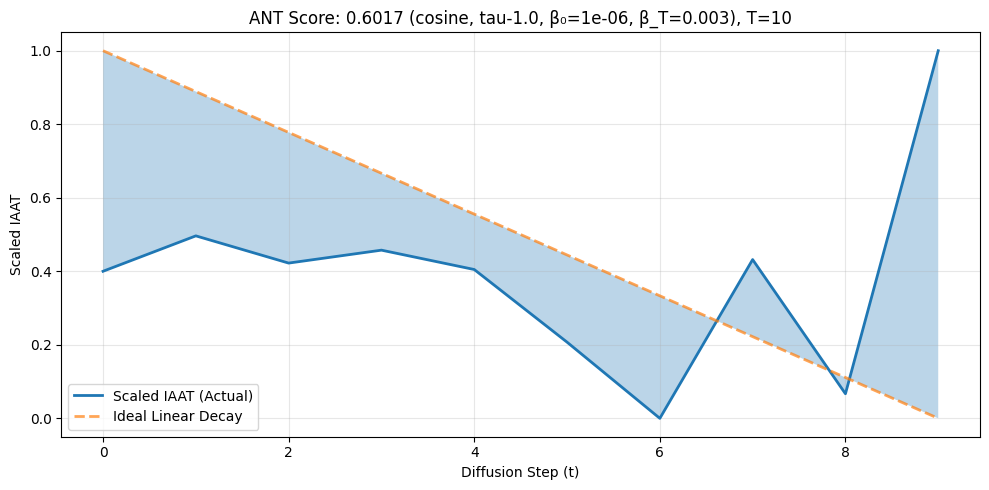

T=10, tau=1.1, β₀=1e-06, β_T=0.003
T=10, tau=1.2, β₀=1e-06, β_T=0.003
T=10, tau=1.3, β₀=1e-06, β_T=0.003
T=10, tau=1.5, β₀=1e-06, β_T=0.003
[New Best] cosine, tau, =1.5, β₀=1e-06, β_T=0.003 → Score: 0.5171


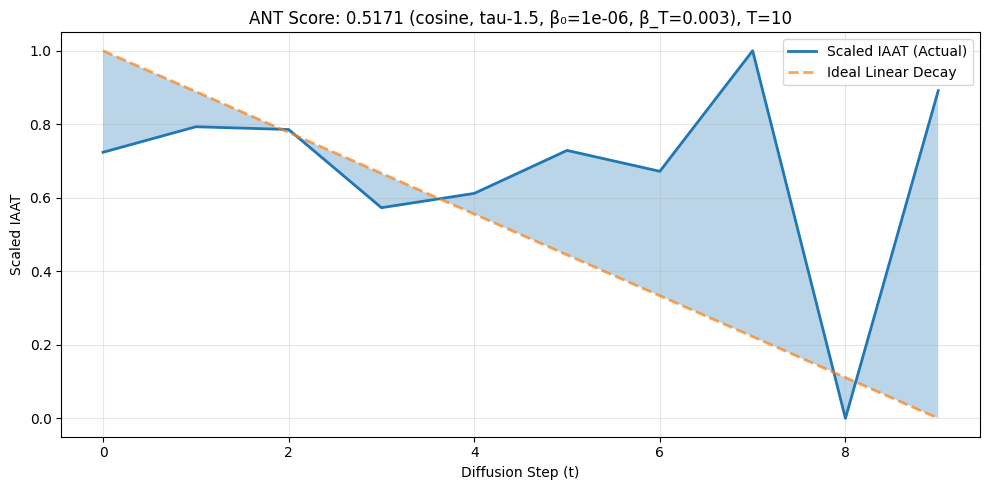

T=10, tau=1.8, β₀=1e-06, β_T=0.003
T=10, tau=0.6, β₀=1e-06, β_T=0.005
T=10, tau=0.7, β₀=1e-06, β_T=0.005
T=10, tau=0.8, β₀=1e-06, β_T=0.005
T=10, tau=0.9, β₀=1e-06, β_T=0.005
T=10, tau=1.0, β₀=1e-06, β_T=0.005
[New Best] cosine, tau, =1.0, β₀=1e-06, β_T=0.005 → Score: 0.4543


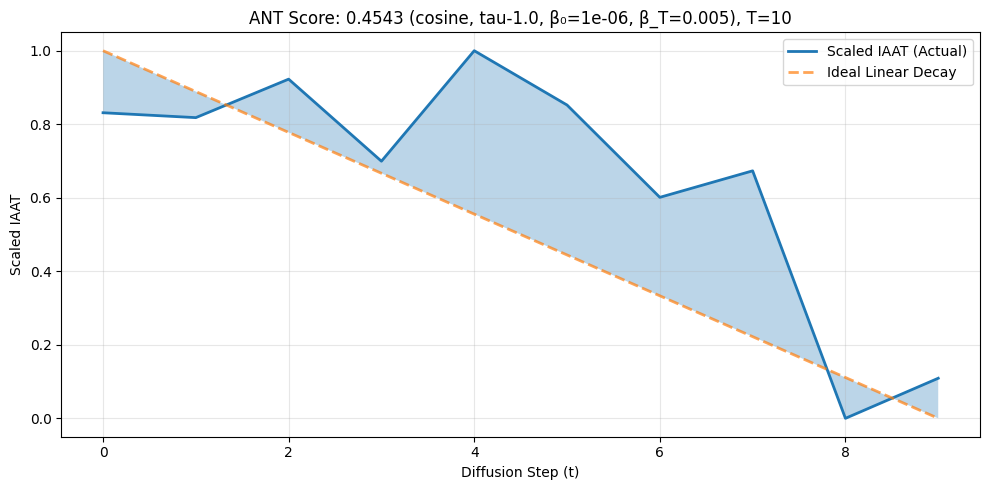

T=10, tau=1.1, β₀=1e-06, β_T=0.005
T=10, tau=1.2, β₀=1e-06, β_T=0.005
T=10, tau=1.3, β₀=1e-06, β_T=0.005
T=10, tau=1.5, β₀=1e-06, β_T=0.005
T=10, tau=1.8, β₀=1e-06, β_T=0.005
T=10, tau=0.6, β₀=1e-06, β_T=0.007
T=10, tau=0.7, β₀=1e-06, β_T=0.007
T=10, tau=0.8, β₀=1e-06, β_T=0.007
T=10, tau=0.9, β₀=1e-06, β_T=0.007
T=10, tau=1.0, β₀=1e-06, β_T=0.007
[New Best] cosine, tau, =1.0, β₀=1e-06, β_T=0.007 → Score: 0.4261


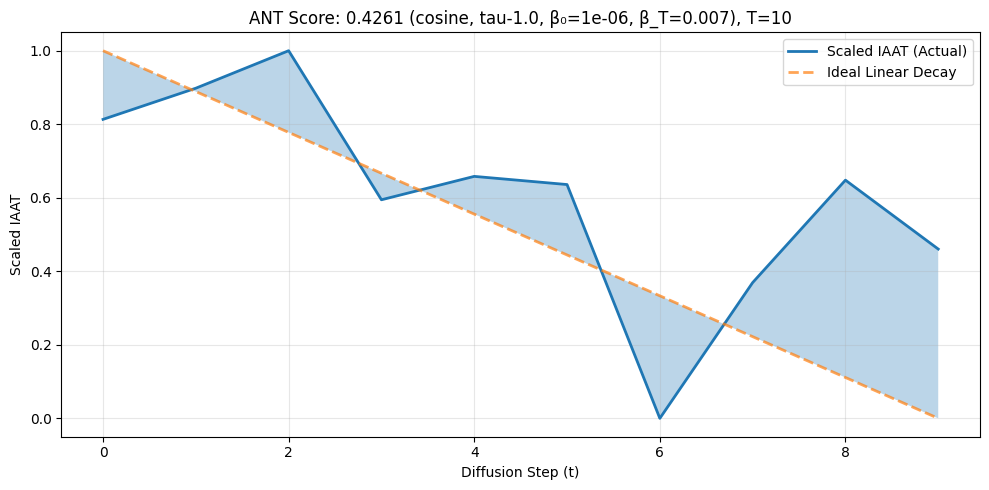

T=10, tau=1.1, β₀=1e-06, β_T=0.007
T=10, tau=1.2, β₀=1e-06, β_T=0.007
T=10, tau=1.3, β₀=1e-06, β_T=0.007
T=10, tau=1.5, β₀=1e-06, β_T=0.007
T=10, tau=1.8, β₀=1e-06, β_T=0.007
T=10, tau=0.6, β₀=1e-06, β_T=0.01
T=10, tau=0.7, β₀=1e-06, β_T=0.01
T=10, tau=0.8, β₀=1e-06, β_T=0.01
T=10, tau=0.9, β₀=1e-06, β_T=0.01
T=10, tau=1.0, β₀=1e-06, β_T=0.01
T=10, tau=1.1, β₀=1e-06, β_T=0.01
T=10, tau=1.2, β₀=1e-06, β_T=0.01
T=10, tau=1.3, β₀=1e-06, β_T=0.01
T=10, tau=1.5, β₀=1e-06, β_T=0.01
T=10, tau=1.8, β₀=1e-06, β_T=0.01
T=10, tau=0.6, β₀=1e-06, β_T=0.015
T=10, tau=0.7, β₀=1e-06, β_T=0.015
T=10, tau=0.8, β₀=1e-06, β_T=0.015
T=10, tau=0.9, β₀=1e-06, β_T=0.015
T=10, tau=1.0, β₀=1e-06, β_T=0.015
T=10, tau=1.1, β₀=1e-06, β_T=0.015
T=10, tau=1.2, β₀=1e-06, β_T=0.015
T=10, tau=1.3, β₀=1e-06, β_T=0.015
T=10, tau=1.5, β₀=1e-06, β_T=0.015
T=10, tau=1.8, β₀=1e-06, β_T=0.015
T=10, tau=0.6, β₀=1e-06, β_T=0.02
T=10, tau=0.7, β₀=1e-06, β_T=0.02
T=10, tau=0.8, β₀=1e-06, β_T=0.02
T=10, tau=0.9, β₀=1e-06, β_T=0.02

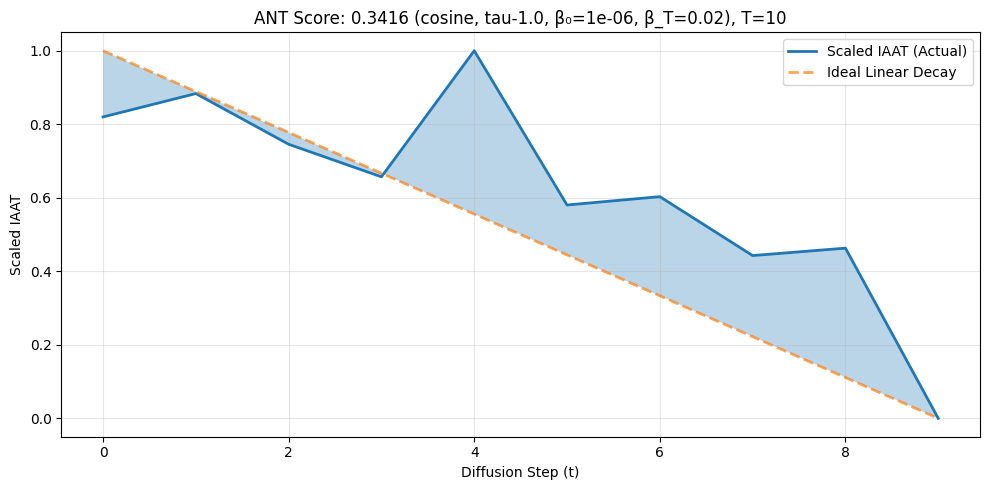

T=10, tau=1.1, β₀=1e-06, β_T=0.02
T=10, tau=1.2, β₀=1e-06, β_T=0.02
T=10, tau=1.3, β₀=1e-06, β_T=0.02
T=10, tau=1.5, β₀=1e-06, β_T=0.02
T=10, tau=1.8, β₀=1e-06, β_T=0.02
T=10, tau=0.6, β₀=1e-06, β_T=0.03
T=10, tau=0.7, β₀=1e-06, β_T=0.03
T=10, tau=0.8, β₀=1e-06, β_T=0.03
T=10, tau=0.9, β₀=1e-06, β_T=0.03
T=10, tau=1.0, β₀=1e-06, β_T=0.03
T=10, tau=1.1, β₀=1e-06, β_T=0.03
T=10, tau=1.2, β₀=1e-06, β_T=0.03
T=10, tau=1.3, β₀=1e-06, β_T=0.03
T=10, tau=1.5, β₀=1e-06, β_T=0.03
T=10, tau=1.8, β₀=1e-06, β_T=0.03
T=10, tau=0.6, β₀=1e-06, β_T=0.05
T=10, tau=0.7, β₀=1e-06, β_T=0.05
T=10, tau=0.8, β₀=1e-06, β_T=0.05
T=10, tau=0.9, β₀=1e-06, β_T=0.05
T=10, tau=1.0, β₀=1e-06, β_T=0.05
T=10, tau=1.1, β₀=1e-06, β_T=0.05
T=10, tau=1.2, β₀=1e-06, β_T=0.05
T=10, tau=1.3, β₀=1e-06, β_T=0.05
T=10, tau=1.5, β₀=1e-06, β_T=0.05
T=10, tau=1.8, β₀=1e-06, β_T=0.05
T=10, tau=0.6, β₀=1e-06, β_T=0.08
T=10, tau=0.7, β₀=1e-06, β_T=0.08
T=10, tau=0.8, β₀=1e-06, β_T=0.08
T=10, tau=0.9, β₀=1e-06, β_T=0.08
T=10, tau=1.0,

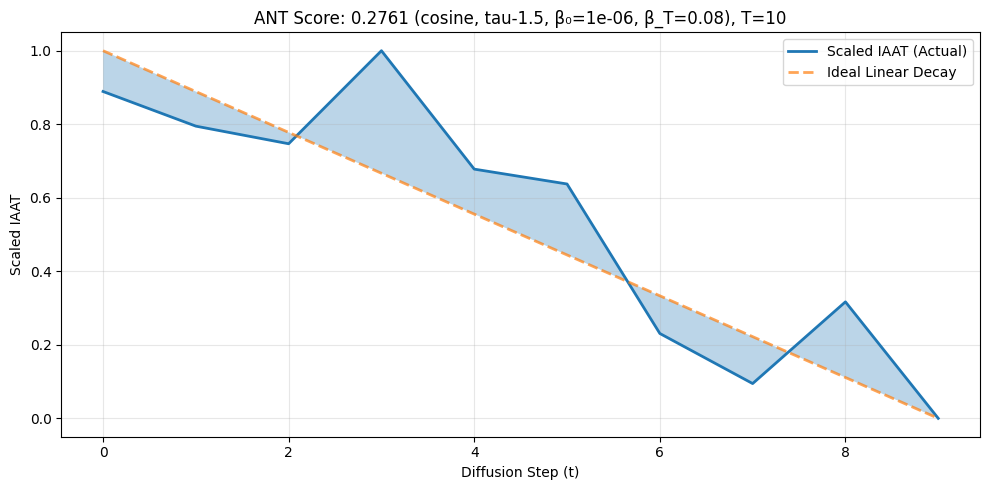

T=10, tau=1.8, β₀=1e-06, β_T=0.08
T=10, tau=0.6, β₀=1e-06, β_T=0.1
T=10, tau=0.7, β₀=1e-06, β_T=0.1
T=10, tau=0.8, β₀=1e-06, β_T=0.1
T=10, tau=0.9, β₀=1e-06, β_T=0.1
T=10, tau=1.0, β₀=1e-06, β_T=0.1
T=10, tau=1.1, β₀=1e-06, β_T=0.1
T=10, tau=1.2, β₀=1e-06, β_T=0.1
T=10, tau=1.3, β₀=1e-06, β_T=0.1
T=10, tau=1.5, β₀=1e-06, β_T=0.1
T=10, tau=1.8, β₀=1e-06, β_T=0.1
T=10, tau=0.6, β₀=1e-06, β_T=0.15
T=10, tau=0.7, β₀=1e-06, β_T=0.15
T=10, tau=0.8, β₀=1e-06, β_T=0.15
T=10, tau=0.9, β₀=1e-06, β_T=0.15
T=10, tau=1.0, β₀=1e-06, β_T=0.15
T=10, tau=1.1, β₀=1e-06, β_T=0.15
T=10, tau=1.2, β₀=1e-06, β_T=0.15
T=10, tau=1.3, β₀=1e-06, β_T=0.15
T=10, tau=1.5, β₀=1e-06, β_T=0.15
T=10, tau=1.8, β₀=1e-06, β_T=0.15
T=10, tau=0.6, β₀=1e-06, β_T=0.2
T=10, tau=0.7, β₀=1e-06, β_T=0.2
T=10, tau=0.8, β₀=1e-06, β_T=0.2
T=10, tau=0.9, β₀=1e-06, β_T=0.2
T=10, tau=1.0, β₀=1e-06, β_T=0.2
[New Best] cosine, tau, =1.0, β₀=1e-06, β_T=0.2 → Score: 0.1820


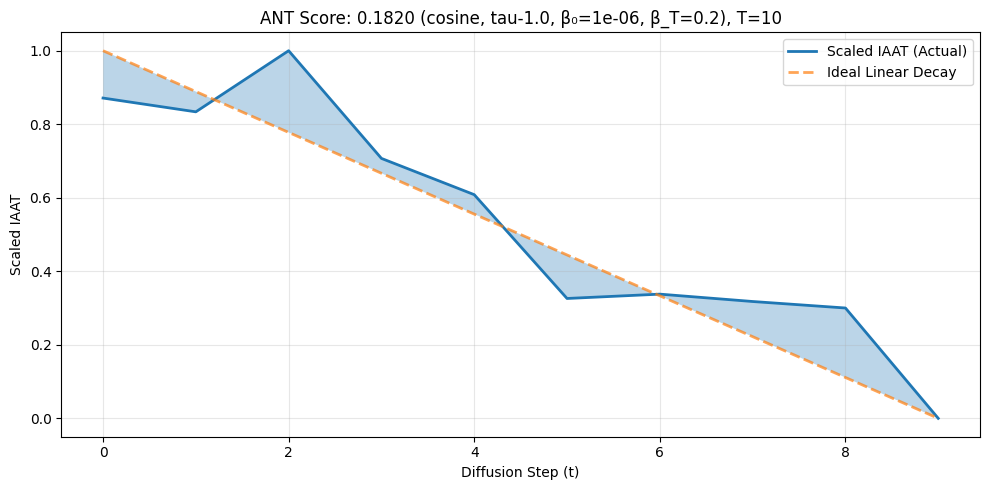

T=10, tau=1.1, β₀=1e-06, β_T=0.2
T=10, tau=1.2, β₀=1e-06, β_T=0.2
T=10, tau=1.3, β₀=1e-06, β_T=0.2
T=10, tau=1.5, β₀=1e-06, β_T=0.2
T=10, tau=1.8, β₀=1e-06, β_T=0.2
T=10, tau=0.6, β₀=1e-06, β_T=0.3
T=10, tau=0.7, β₀=1e-06, β_T=0.3
T=10, tau=0.8, β₀=1e-06, β_T=0.3
T=10, tau=0.9, β₀=1e-06, β_T=0.3
T=10, tau=1.0, β₀=1e-06, β_T=0.3
T=10, tau=1.1, β₀=1e-06, β_T=0.3
T=10, tau=1.2, β₀=1e-06, β_T=0.3
T=10, tau=1.3, β₀=1e-06, β_T=0.3
T=10, tau=1.5, β₀=1e-06, β_T=0.3
T=10, tau=1.8, β₀=1e-06, β_T=0.3
T=10, tau=0.6, β₀=3e-06, β_T=0.003
T=10, tau=0.7, β₀=3e-06, β_T=0.003
T=10, tau=0.8, β₀=3e-06, β_T=0.003
T=10, tau=0.9, β₀=3e-06, β_T=0.003
T=10, tau=1.0, β₀=3e-06, β_T=0.003
T=10, tau=1.1, β₀=3e-06, β_T=0.003
T=10, tau=1.2, β₀=3e-06, β_T=0.003
T=10, tau=1.3, β₀=3e-06, β_T=0.003
T=10, tau=1.5, β₀=3e-06, β_T=0.003
T=10, tau=1.8, β₀=3e-06, β_T=0.003
T=10, tau=0.6, β₀=3e-06, β_T=0.005
T=10, tau=0.7, β₀=3e-06, β_T=0.005
T=10, tau=0.8, β₀=3e-06, β_T=0.005
T=10, tau=0.9, β₀=3e-06, β_T=0.005
T=10, tau=1.0, 

In [ ]:
beta_0_list = [
    1e-6,
    3e-6,
    1e-5,
    3e-5,
    1e-4,
    3e-4
]
beta_T_list = [
    0.003,
    0.005,
    0.007,
    0.01,
    0.015,
    0.02,
    0.03,
    0.05,
    0.08,
    0.1,
    0.15,
    0.2,
    0.3
]
tau_list = [
    0.6,
    0.7,
    0.8,
    0.9,
    1.0,
    1.1,
    1.2,
    1.3,
    1.5,
    1.8
]

results = []
best_score = float('inf')
sched = 'cosine'

for T in [10, 20, 50, 75]:
    for beta_0 in beta_0_list:
        for beta_T in beta_T_list:
            for tau in tau_list:
                print(f"T={T}, tau={tau}, β₀={beta_0}, β_T={beta_T}")
                betas_test = return_betas(sched, tau, T, beta_0=beta_0, beta_T=beta_T)
                out_test = get_scheduler_utils(T, betas_test)
                _, _, _, sqrt_ac, sqrt_omac, _ = out_test
                
                TS_acf_test = []
                for ts in TS:
                    ts_p = preprocess_data(ts)
                    acf_val = return_acf(ts_p, sqrt_ac, sqrt_omac, T)
                    TS_acf_test.append(acf_val)

                TS_acf_test = np.array(TS_acf_test)
                
                IAAT_t, scaled_IAAT = get_mIAAT_list(TS_acf_test, np.var(TS, axis=1))
                score = calculate_ANT_score(IAAT_t, scaled_IAAT)
                results.append({'scheduler': sched, 'T': T, 'tau':tau, 'beta_0': beta_0, 'beta_T': beta_T, 'ANT_score': score})
                
                # Best가 갱신될 때마다 그래프 출력
                if score < best_score:
                    best_score = score
                    print(f"[New Best] {sched}, tau, ={tau}, β₀={beta_0}, β_T={beta_T} → Score: {score:.4f}")
                    
                    plt.figure(figsize=(10, 5))
                    plt.plot(scaled_IAAT, label='Scaled IAAT (Actual)', linewidth=2)
                    plt.plot(np.linspace(1, 0, len(scaled_IAAT)), '--', label='Ideal Linear Decay', linewidth=2, alpha=0.7)
                    plt.fill_between(range(len(scaled_IAAT)), scaled_IAAT, np.linspace(1, 0, len(scaled_IAAT)), alpha=0.3)
                    plt.xlabel('Diffusion Step (t)')
                    plt.ylabel('Scaled IAAT')
                    plt.title(f"ANT Score: {score:.4f} ({sched}, tau={tau}, β₀={beta_0}, β_T={beta_T}), T={T}")
                    plt.legend()
                    plt.grid(True, alpha=0.3)
                    plt.tight_layout()
                    plt.show()
                    gc.collect()

# 결과 출력
results_df = pd.DataFrame(results)
results_df.to_csv(f"{file_manager.get_result_file(f'{sched}_ANT_score')}")
